## Import Libraries

In [ ]:
import sys
sys.path.append('..')
import numpy as np
import pandas as pd
from src import descriptors
from src import fingerprint
import seaborn as sns
import matplotlib.pyplot as plt


## Load Descriptor Dataset


In [ ]:
df= pd.read_csv("../data/output/extended_descriptors.csv")
df

,Unnamed: 0,Smile,ID,IC50(nM),pIC50
0,0,C#CCOc1cnc(/C(F)=C/c2ccc(F)c([C@]3(C)CS(=O)(=O...,CHEMBL6010325,3.00,8.522879
1,1,C#CCOc1cnc(/C(F)=C/c2ccc(F)c([C@]34CN(C(=O)OC(...,CHEMBL5905447,2.62,8.581699
2,2,CC#Cc1cncc(-c2ccc3c(c2)[C@@]2(COC(N)=N2)c2cc(-...,C27H18FN5O2,0.43,9.366532
3,3,CC#Cc1cncc(-c2ccc3c(c2)[C@@]2(COC(N)=N2)c2cc(C...,C27H22N4O3,0.46,9.337242
4,4,CC#Cc1cncc(-c2ccc3c(c2)[C@@]2(COC(N)=N2)c2cc(C...,C27H22N4O3,0.31,9.508638
...,...,...,...,...,...
172,172,NC1=N[C@@]2(CO1)c1cc(NC(=O)c3ccc(Cl)cn3)ccc1Oc...,C23H18ClN5O3,3.60,8.443697
173,173,NC1=N[C@@]2(CO1)c1cc(NC(=O)c3ccc(Cl)cn3)ccc1Oc...,C25H22ClN5O4,0.57,9.244125
174,174,NC1=N[C@@]2(CO1)c1cc(NC(=O)c3ccc(Cl)cn3)ccc1Oc...,C20H13Cl2N5O3,21.00,7.677781
175,175,NC1=N[C@@]2(c3cc(-c4cccnc4F)ccc3Oc3c(F)cc([N+]...,CHEMBL4109073,0.60,9.221849


In [101]:
dsc= Descriptors.calculate_extended_descriptors(df, smiles_column="Smile")
dsc

,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,ExactMolWt,NumValenceElectrons,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
0,14.803745,14.803745,0.007250,-3.652177,0.670633,23.333333,472.517,450.341,472.138068,172,...,0,0,1,1,0,0,0,0,0,0
1,15.242830,15.242830,0.019417,-1.105593,0.585889,21.555556,513.570,488.370,513.164617,188,...,1,0,0,1,0,0,0,0,0,0
2,13.781613,13.781613,0.087412,-0.943911,0.349535,17.371429,463.472,445.328,463.144453,170,...,0,0,0,0,0,0,0,0,0,0
3,6.278086,6.278086,0.157097,-0.828326,0.593360,20.147059,450.498,428.322,450.169191,168,...,0,0,0,0,0,0,0,0,0,0
4,6.284645,6.284645,0.161788,-0.818760,0.593360,20.147059,450.498,428.322,450.169191,168,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
172,12.654788,12.654788,0.118877,-0.862262,0.628253,20.593750,447.882,429.738,447.109817,160,...,0,0,0,0,0,0,0,0,0,0
173,12.737734,12.737734,0.104659,-0.907622,0.568150,20.885714,491.935,469.759,491.136032,178,...,0,0,0,0,0,0,0,0,0,0
174,12.555442,12.555442,0.056979,-0.959484,0.585416,18.666667,442.262,429.158,441.039545,150,...,0,0,0,0,0,0,0,0,0,0
175,15.651898,15.651898,0.048905,-1.297290,0.346568,19.722222,485.474,466.322,485.153207,178,...,0,0,0,0,0,0,0,0,0,0


### Data Analysis 

In [102]:
print(dsc.shape)
print(dsc.info)


(177, 217)
<bound method DataFrame.info of      MaxAbsEStateIndex  MaxEStateIndex  MinAbsEStateIndex  MinEStateIndex  \
0            14.803745       14.803745           0.007250       -3.652177   
1            15.242830       15.242830           0.019417       -1.105593   
2            13.781613       13.781613           0.087412       -0.943911   
3             6.278086        6.278086           0.157097       -0.828326   
4             6.284645        6.284645           0.161788       -0.818760   
..                 ...             ...                ...             ...   
172          12.654788       12.654788           0.118877       -0.862262   
173          12.737734       12.737734           0.104659       -0.907622   
174          12.555442       12.555442           0.056979       -0.959484   
175          15.651898       15.651898           0.048905       -1.297290   
176          15.540907       15.540907           0.016012       -1.928054   

          qed        SPS    MolW

In [103]:
dsc.notnull().sum()

MaxAbsEStateIndex    177
MaxEStateIndex       177
MinAbsEStateIndex    177
MinEStateIndex       177
qed                  177
                    ... 
fr_thiazole          177
fr_thiocyan          177
fr_thiophene         177
fr_unbrch_alkane     177
fr_urea              177
Length: 217, dtype: int64

In [104]:
dsc.isnull().sum()

MaxAbsEStateIndex    0
MaxEStateIndex       0
MinAbsEStateIndex    0
MinEStateIndex       0
qed                  0
                    ..
fr_thiazole          0
fr_thiocyan          0
fr_thiophene         0
fr_unbrch_alkane     0
fr_urea              0
Length: 217, dtype: int64

In [105]:
dsc.describe().T

,count,mean,std,min,25%,50%,75%,max
MaxAbsEStateIndex,177.0,12.487045,2.986793,6.167710,12.705712,13.782625,14.101339,15.651898
MaxEStateIndex,177.0,12.487045,2.986793,6.167710,12.705712,13.782625,14.101339,15.651898
MinAbsEStateIndex,177.0,0.076271,0.064879,0.000297,0.026506,0.064606,0.107579,0.377372
MinEStateIndex,177.0,-1.573625,1.208344,-4.776651,-1.573089,-0.987440,-0.853454,-0.487332
qed,177.0,0.660573,0.209698,0.042501,0.593360,0.736495,0.797302,0.915960
...,...,...,...,...,...,...,...,...
fr_thiazole,177.0,0.022599,0.149042,0.000000,0.000000,0.000000,0.000000,1.000000
fr_thiocyan,177.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
fr_thiophene,177.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
fr_unbrch_alkane,177.0,0.056497,0.276289,0.000000,0.000000,0.000000,0.000000,2.000000


In [106]:
dsc.duplicated().sum()

np.int64(1)

In [107]:
dsc[dsc.duplicated(keep=False)]

,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,ExactMolWt,NumValenceElectrons,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
14,13.595406,13.595406,0.09781,-1.573089,0.042501,15.460317,893.005,828.493,892.454199,352,...,0,0,0,0,0,0,0,0,0,0
15,13.595406,13.595406,0.09781,-1.573089,0.042501,15.460317,893.005,828.493,892.454199,352,...,0,0,0,0,0,0,0,0,0,0


Remove Constant Features

In [108]:
dsc.nunique()

MaxAbsEStateIndex    174
MaxEStateIndex       174
MinAbsEStateIndex    175
MinEStateIndex       175
qed                  168
                    ... 
fr_thiazole            2
fr_thiocyan            1
fr_thiophene           1
fr_unbrch_alkane       3
fr_urea                1
Length: 217, dtype: int64

In [109]:
constant_features=[i for i in dsc.columns if dsc[i].nunique()==1]
print(constant_features)
print(f"Removed {len(constant_features)} constant features.")

['NumRadicalElectrons', 'SMR_VSA8', 'SlogP_VSA9', 'NumBridgeheadAtoms', 'fr_ArN', 'fr_Ar_OH', 'fr_C_S', 'fr_HOCCN', 'fr_SH', 'fr_aldehyde', 'fr_alkyl_carbamate', 'fr_azide', 'fr_azo', 'fr_barbitur', 'fr_benzodiazepine', 'fr_diazo', 'fr_dihydropyridine', 'fr_epoxide', 'fr_furan', 'fr_hdrzine', 'fr_hdrzone', 'fr_imide', 'fr_isocyan', 'fr_isothiocyan', 'fr_lactam', 'fr_lactone', 'fr_nitro', 'fr_nitro_arom', 'fr_nitro_arom_nonortho', 'fr_nitroso', 'fr_oxime', 'fr_phenol', 'fr_phenol_noOrthoHbond', 'fr_phos_acid', 'fr_phos_ester', 'fr_prisulfonamd', 'fr_quatN', 'fr_thiocyan', 'fr_thiophene', 'fr_urea']
Removed 40 constant features.


In [110]:
dsc=dsc.drop(columns=constant_features)

In [111]:
dsc.shape

(177, 177)

In [112]:
def remove_costant_features(df):
     """
    Remove constant features from a dataframe.
    """
    constant_features=[col for col in dsc.columns if dsc[i].nunique()==1] 

    return  df.drop(columns=constant_features) , constant_features

IndentationError: unindent does not match any outer indentation level (<tokenize>, line 5)

In [ ]:
dsc, constant_features = remove_constant_features(dsc)

print(f"{len(constant_features)} constant features removed.")

NameError: name 'remove_constant_features' is not defined

In [113]:
dsc.describe().T

,count,mean,std,min,25%,50%,75%,max
MaxAbsEStateIndex,177.0,12.487045,2.986793,6.167710,12.705712,13.782625,14.101339,15.651898
MaxEStateIndex,177.0,12.487045,2.986793,6.167710,12.705712,13.782625,14.101339,15.651898
MinAbsEStateIndex,177.0,0.076271,0.064879,0.000297,0.026506,0.064606,0.107579,0.377372
MinEStateIndex,177.0,-1.573625,1.208344,-4.776651,-1.573089,-0.987440,-0.853454,-0.487332
qed,177.0,0.660573,0.209698,0.042501,0.593360,0.736495,0.797302,0.915960
...,...,...,...,...,...,...,...,...
fr_sulfone,177.0,0.028249,0.166152,0.000000,0.000000,0.000000,0.000000,1.000000
fr_term_acetylene,177.0,0.011299,0.105996,0.000000,0.000000,0.000000,0.000000,1.000000
fr_tetrazole,177.0,0.011299,0.105996,0.000000,0.000000,0.000000,0.000000,1.000000
fr_thiazole,177.0,0.022599,0.149042,0.000000,0.000000,0.000000,0.000000,1.000000


Correlation Filter

In [114]:
dsc.corr()

,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,ExactMolWt,NumValenceElectrons,...,fr_piperzine,fr_priamide,fr_pyridine,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_unbrch_alkane
MaxAbsEStateIndex,1.000000,1.000000,-0.382382,-0.336218,-0.102579,-0.115440,0.219488,0.230756,0.219985,0.205270,...,0.067870,0.065700,-0.025399,0.251358,0.140649,0.129953,0.091036,0.047773,0.036496,-0.005314
MaxEStateIndex,1.000000,1.000000,-0.382382,-0.336218,-0.102579,-0.115440,0.219488,0.230756,0.219985,0.205270,...,0.067870,0.065700,-0.025399,0.251358,0.140649,0.129953,0.091036,0.047773,0.036496,-0.005314
MinAbsEStateIndex,-0.382382,-0.382382,1.000000,0.006119,-0.108194,-0.121151,0.040289,0.054221,0.039596,-0.001003,...,0.023003,0.006457,0.033275,-0.099216,-0.112629,-0.134369,-0.104000,-0.046015,0.033926,-0.145211
MinEStateIndex,-0.336218,-0.336218,0.006119,1.000000,0.073111,0.100980,-0.164019,-0.183713,-0.164110,-0.131071,...,0.017837,0.015414,0.071422,0.089425,-0.401518,-0.293624,-0.071445,-0.026170,0.019579,0.100433
qed,-0.102579,-0.102579,-0.108194,0.073111,1.000000,0.809327,-0.900482,-0.900805,-0.900446,-0.878090,...,-0.191860,-0.387739,-0.081582,-0.060979,-0.065852,0.045901,-0.016519,-0.299275,0.083408,-0.121569
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
fr_sulfone,0.129953,0.129953,-0.134369,-0.293624,0.045901,-0.073987,-0.002044,0.012150,-0.002374,-0.046924,...,-0.022388,-0.029070,0.077377,0.042895,-0.037096,1.000000,0.304392,-0.018227,-0.025926,-0.034963
fr_term_acetylene,0.091036,0.091036,-0.104000,-0.071445,-0.016519,-0.081581,0.038084,0.046355,0.038196,0.020652,...,-0.014037,-0.018227,-0.052117,0.126075,-0.023259,0.304392,1.000000,-0.011429,-0.016256,-0.021922
fr_tetrazole,0.047773,0.047773,-0.046015,-0.026170,-0.299275,-0.247370,0.307978,0.311178,0.308103,0.304406,...,-0.014037,-0.018227,-0.052117,-0.039223,-0.023259,-0.018227,-0.011429,1.000000,-0.016256,-0.021922
fr_thiazole,0.036496,0.036496,0.033926,0.019579,0.083408,0.042800,-0.039908,-0.033414,-0.039786,-0.063612,...,-0.019966,-0.025926,0.045151,0.179324,-0.033083,-0.025926,-0.016256,-0.016256,1.000000,-0.031182


In [120]:
corr_max=dsc.corr().abs()

upper=corr_max.where(np.triu(np.ones(corr_max.shape),k=1).astype(bool))

to_drop=[col for col in upper.columns if any(upper[col]>0.90) ]

print(to_drop)

dsc=dsc.drop(columns=to_drop)

['MolWt', 'MaxAbsPartialCharge', 'BCUT2D_LOGPHI', 'Chi4n', 'HallKierAlpha', 'SlogP_VSA1', 'SlogP_VSA5', 'TPSA', 'EState_VSA1', 'VSA_EState2', 'VSA_EState3', 'NumAromaticRings', 'NumHeteroatoms', 'NumHeterocycles', 'NumSpiroAtoms', 'fr_Ar_N', 'fr_nitrile']


In [121]:
dsc.shape

(177, 121)

<Axes: >

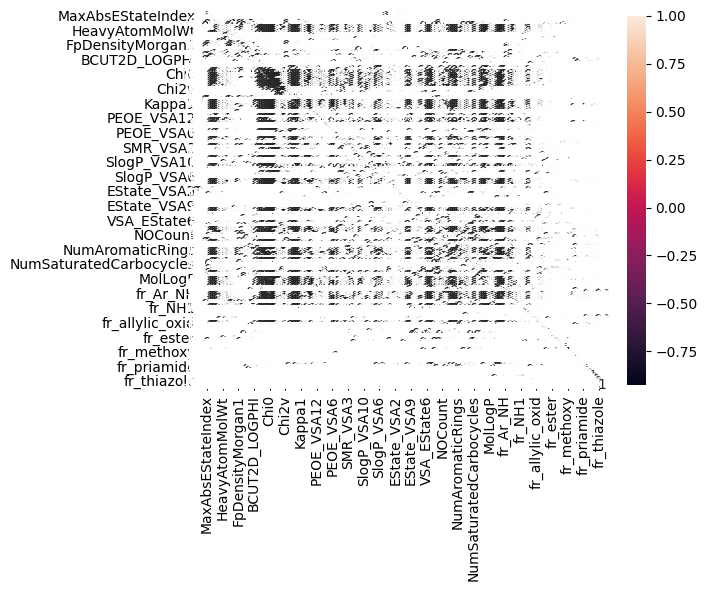

In [116]:
plt.Figure(figsize=[12,12])
sns.heatmap(dsc.corr(), annot=True)